# Device selection

In [60]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_aer import AerSimulator

channel = "ibm_quantum"
# device = "ibm_kyiv"
# device = "ibm_brisbane"
device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
# device = "ibm_marrakesh"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)
simulator = AerSimulator.from_backend(backend)

# Simulation settings

In [61]:
from z2chain.gdd import zero_mean
from functools import partial
import numpy as np

L = 5
J = 2
h = 0.8
lamb = 1

x_basis = False

fractional_gates = False

particle_position = 2

final_time = 5
dt = 0.1
steps = 40
desired_error = 1e-2

shots = 75000
confidence = 0.7

odr = True
flip_threshold = None
# g_func = partial(counteract_rotation, ham_param=J)
# g_func = partial(constant, angle=np.pi)
# g_func = random
g_func = zero_mean
# g_func = None

# Trotter truth

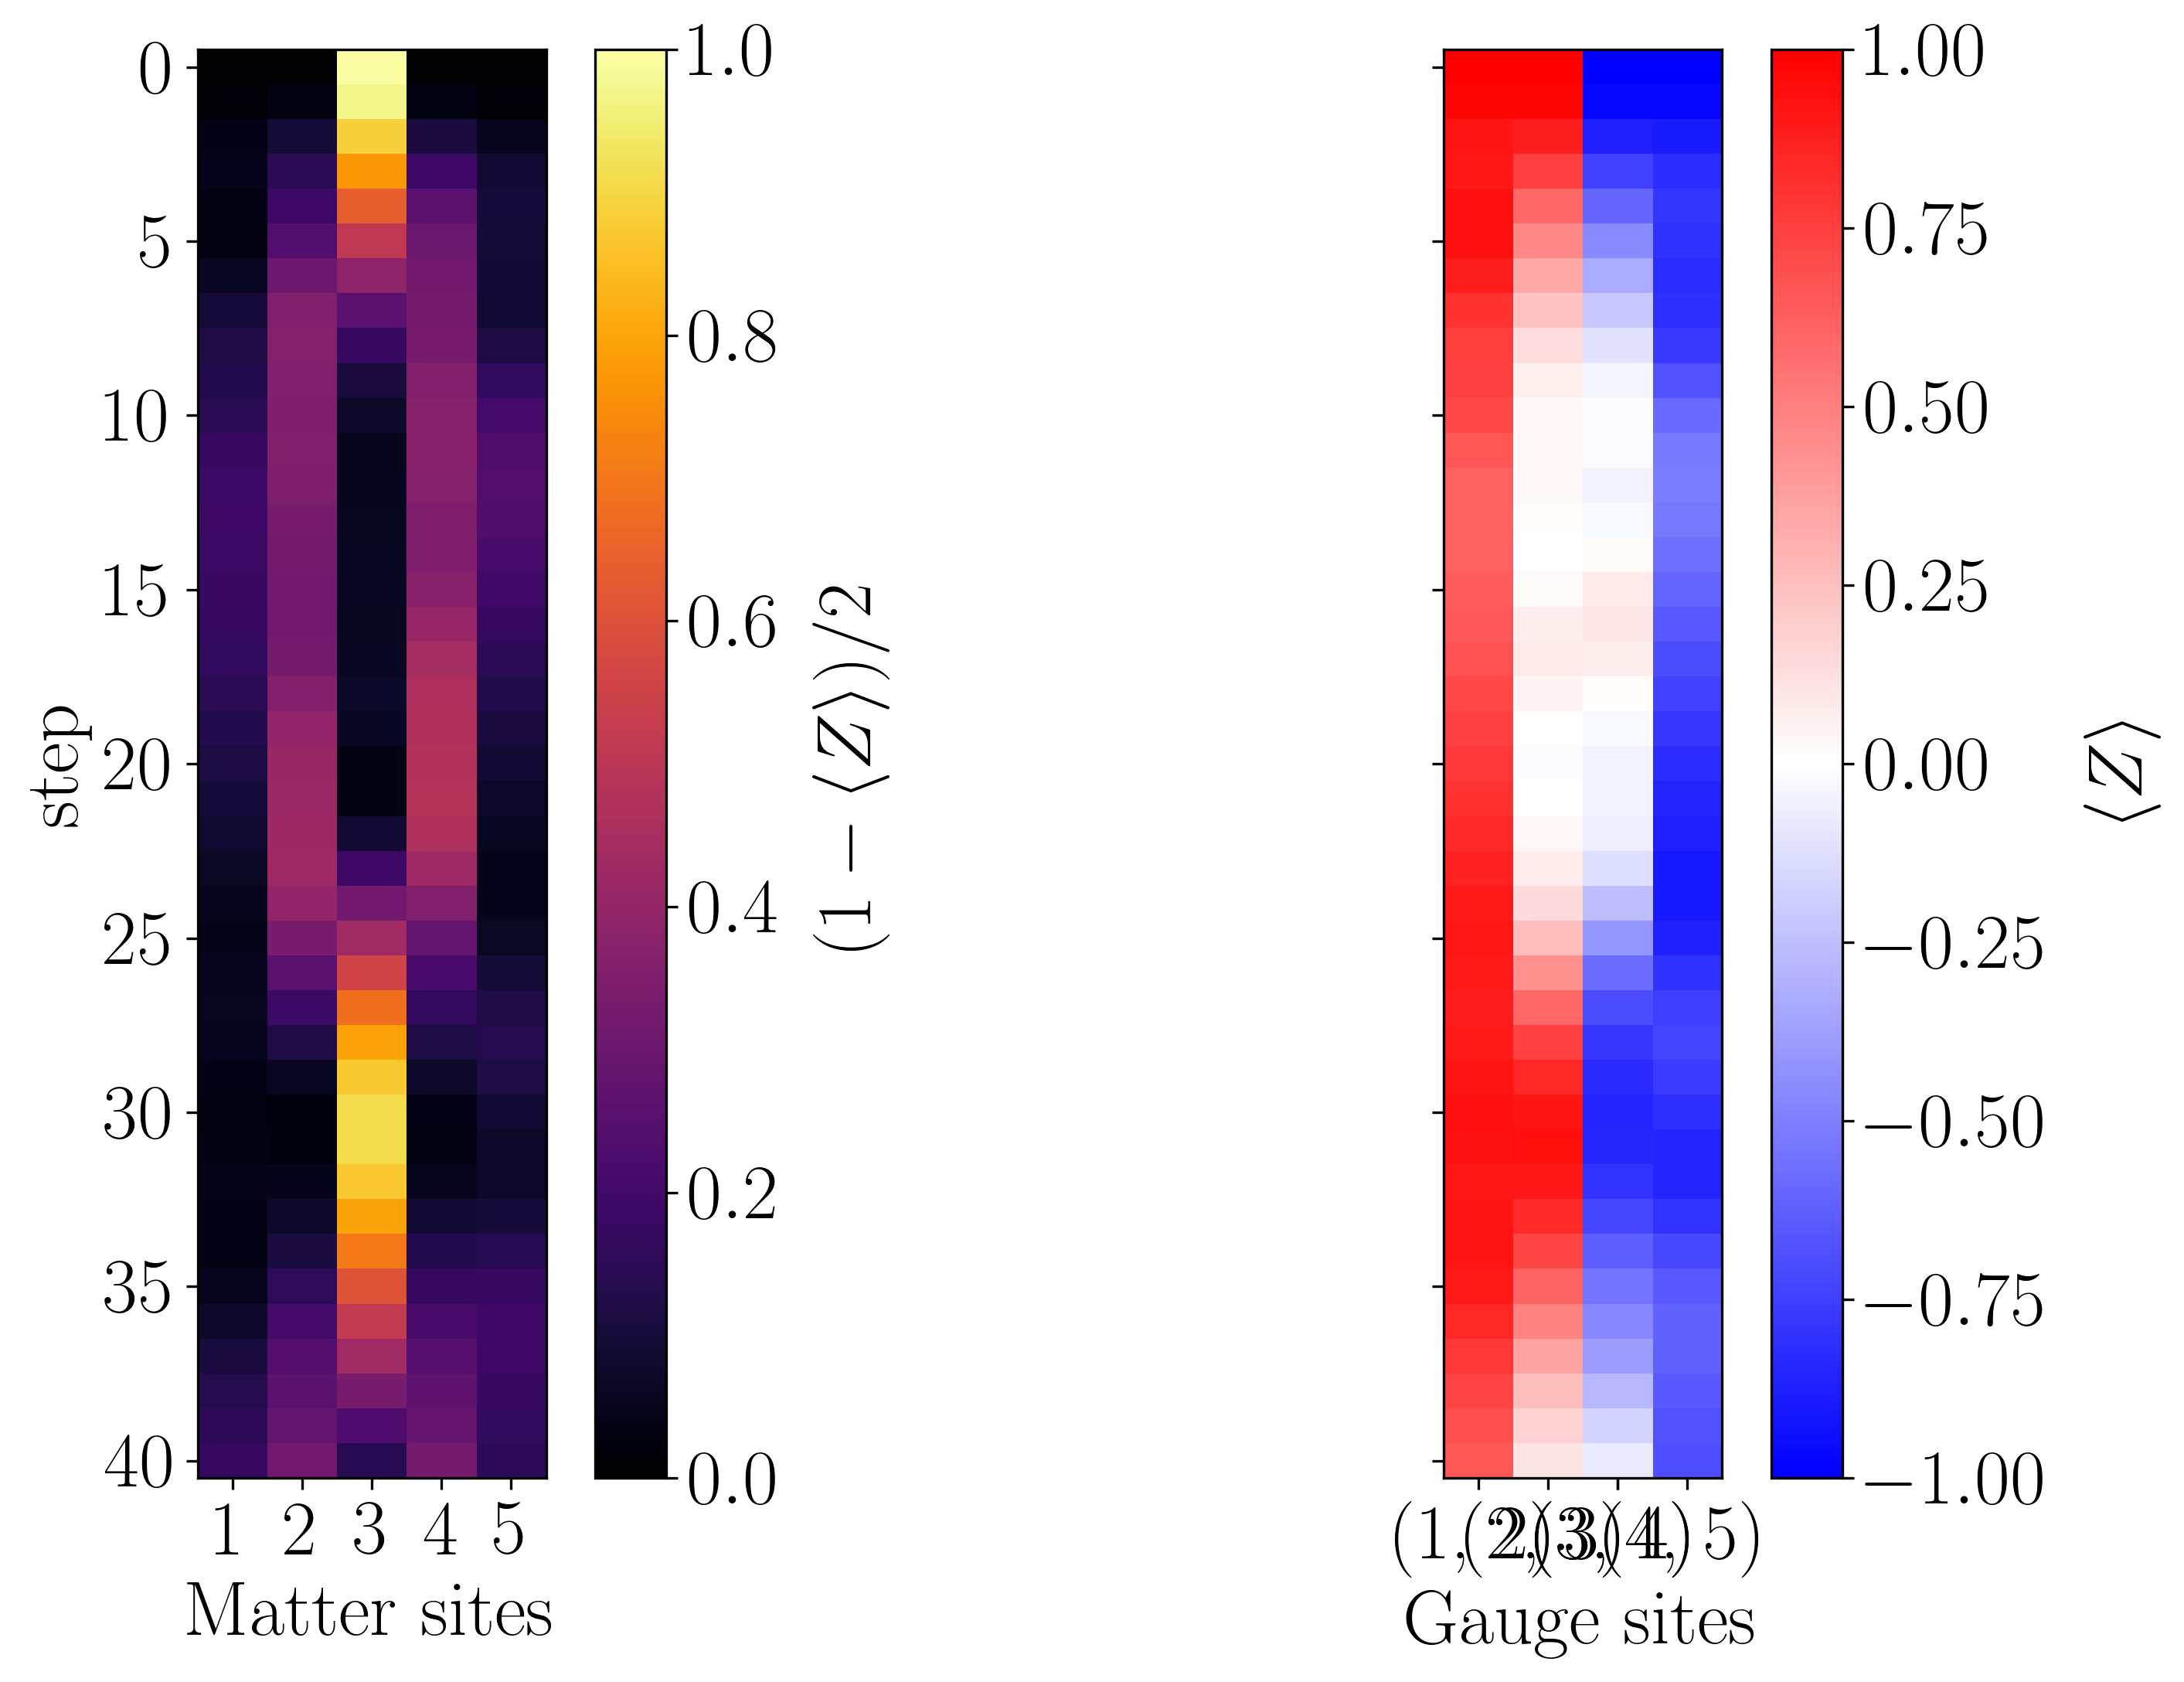

In [62]:
from z2chain.plotting import x_t_separated_plot
import z2chain.exact as exact

exact_observables = exact.singlep_quench_trotter2_simulation(L, J, h, lamb, particle_position, final_time/steps, steps)

x_t_separated_plot(exact_observables)

# Variable noise amplification circuits

In [63]:
import numpy as np

def get_noise_amplification_factors(min_factor, max_factor, steps, npoints):
    factors = np.zeros((steps, npoints))
    for i in range(steps):
        this_max_factor = min_factor + (max_factor - min_factor) * i / (steps - 1)
        factors[i] = np.linspace(1, this_max_factor, npoints)
    return factors[::-1, :]

In [64]:
from qiskit import generate_preset_pass_manager, QuantumCircuit
from utils.circs import numpy_array_of_circuits
import z2chain.circs as circs

def singlep_quench_simulation_circuits_dt_zne(chain_length, J, h, lamb, particle_position, final_time, dt, amplification_levels, backend, optimization_level, g_func=None, layout=None, x_basis=False, force_even=False, barriers=False, measure=True):
    steps = amplification_levels.shape[0]
    t_arr = np.linspace(0, final_time, steps + 1)
    nlayers_arr = (t_arr[1:] // dt).astype(int)
    nlayers_arr[np.equal(nlayers_arr, 0)] = 1
    if force_even: nlayers_arr[~np.equal(nlayers_arr % 2, 0)] += 1
    dt_arr = t_arr[1:] / nlayers_arr
    trotter_pm = generate_preset_pass_manager(optimization_level=optimization_level, backend=backend, initial_layout=layout)
    state_preparation_logical_circ = circs.single_particle_initial_state(chain_length, particle_position, x_basis=x_basis)
    measured_state_preparation_logical_circ = state_preparation_logical_circ.copy()
    if measure: measured_state_preparation_logical_circ.measure_all()
    logical_time_circs = [[measured_state_preparation_logical_circ]*amplification_levels.shape[1]]
    final_amplification_levels = np.zeros_like(amplification_levels, dtype=float)
    for i, these_amplevels in enumerate(amplification_levels):
        this_time_circs = []
        for j, amplevel in enumerate(these_amplevels):
            this_nlayers = int(np.ceil(nlayers_arr[i]*amplevel))
            final_amplification_levels[i, j] = this_nlayers/nlayers_arr[i]
            this_dt = dt_arr[i]/amplevel
            this_time_circs.append(circs.logical_singlep_quench_simulation_circuit(chain_length, J, h, lamb, particle_position, this_dt, this_nlayers, g_func, x_basis, barriers))
        logical_time_circs.append(this_time_circs)
    logical_time_circs = numpy_array_of_circuits(logical_time_circs)
    physical_time_circs = trotter_pm.run(logical_time_circs.flatten().tolist())
    physical_time_circs = numpy_array_of_circuits(physical_time_circs)
    physical_time_circs = physical_time_circs.reshape(logical_time_circs.shape)
    return physical_time_circs.T, final_amplification_levels

def singlep_quench_odr_compuncomp_circuits_dt_zne(chain_length, J, h, lamb, final_time, dt, amplification_levels, backend, optimization_level, g_func=None, particle_position=None, layout=None, x_basis=False, barriers=False, measure=True):
    steps = amplification_levels.shape[0]
    t_arr = np.linspace(0, final_time, steps + 1)
    nlayers_arr = (t_arr[1:] // dt).astype(int)
    nlayers_arr[np.equal(nlayers_arr, 0)] = 1
    nlayers_arr[~np.equal(nlayers_arr % 2, 0)] += 1
    dt_arr = t_arr[1:] / nlayers_arr
    trotter_pm = generate_preset_pass_manager(optimization_level=optimization_level, backend=backend, initial_layout=layout)
    if particle_position is not None:
        state_preparation_logical_circ = circs.single_particle_initial_state(chain_length, particle_position, x_basis=x_basis)
    else:
        state_preparation_logical_circ = QuantumCircuit(2*chain_length-1)
    measured_state_preparation_logical_circ = state_preparation_logical_circ.copy()
    if measure: measured_state_preparation_logical_circ.measure_all()
    logical_time_circs = [[measured_state_preparation_logical_circ]*amplification_levels.shape[1]]
    final_amplification_levels = np.zeros_like(amplification_levels, dtype=float)
    for i, these_amplevels in enumerate(amplification_levels):
        this_time_circs = []
        for j, amplevel in enumerate(these_amplevels):
            this_nlayers = int(np.ceil(nlayers_arr[i]*amplevel))
            final_amplification_levels[i, j] = this_nlayers/nlayers_arr[i]
            this_dt = dt_arr[i]/amplevel
            this_time_circs.append(circs.logical_singlep_quench_odr_compuncomp_circuit(chain_length, J, h, lamb, particle_position, this_dt, this_nlayers, g_func, x_basis, barriers, measure))
        logical_time_circs.append(this_time_circs)
    logical_time_circs = numpy_array_of_circuits(logical_time_circs)
    physical_time_circs = trotter_pm.run(logical_time_circs.flatten().tolist())
    physical_time_circs = numpy_array_of_circuits(physical_time_circs)
    physical_time_circs = physical_time_circs.reshape(logical_time_circs.shape)
    return physical_time_circs.T, final_amplification_levels

def singlep_quench_simulation_and_odr_compuncomp_circs_zne(chain_length, J, h, lamb, final_time, dt, amplification_levels, backend, optimization_level, g_func=None, particle_position=None, layout=None, x_basis=False, barriers=False, measure=True):
    seed = np.random.randint(100000)
    np.random.seed(seed)
    simulation_circuits, sim_amplification_levels = singlep_quench_simulation_circuits_dt_zne(chain_length, J, h, lamb, particle_position, final_time, dt, amplification_levels, backend, optimization_level, g_func=g_func, layout=layout, x_basis=x_basis, force_even=True, barriers=barriers, measure=measure)
    np.random.seed(seed)
    odr_compuncomp_circuits, odr_amplification_levels = singlep_quench_odr_compuncomp_circuits_dt_zne(chain_length, J, h, lamb, final_time, dt, amplification_levels, backend, optimization_level, g_func=g_func, particle_position=None, layout=layout, x_basis=x_basis, barriers=barriers, measure=measure)
    assert np.all(np.isclose(sim_amplification_levels, odr_amplification_levels)), "Some error occurred and amplification levels are not the same"
    return simulation_circuits, odr_compuncomp_circuits, sim_amplification_levels

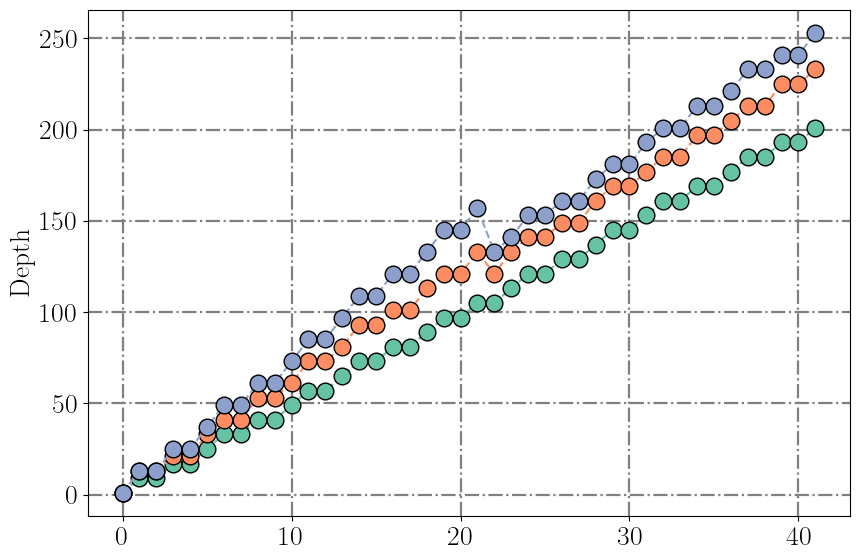

In [65]:
from z2chain.circs import singlep_quench_simulation_and_odr_compuncomp_circs
from z2chain.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.hexec import get_backend_best_qubit_chain
from utils.plotting import plot_circuit_arr_depth
from utils.circs import depth2qb
import matplotlib.pyplot as plt
import numpy as np
import os

noise_amplification_factors = np.vstack((np.tile([1, 1.25, 1.5], (steps//2+1, 1)), (np.tile([1, 1.15, 1.25], (steps//2, 1)))))

optimization_level = 3
layout = get_backend_best_qubit_chain(backend, 2*L-1)

circs_args = (L, J, h, lamb, final_time, dt, noise_amplification_factors, backend, optimization_level, g_func, particle_position, layout, x_basis, False, True)
circuits, odr_circuits, final_amplification_levels = singlep_quench_simulation_and_odr_compuncomp_circs_zne(*circs_args)
observable_generating_funcs = [lambda nqubits, i=i: local_pauli_x(nqubits, i) if x_basis else local_pauli_z(nqubits, i) for i in range(2*L-1)]
postselection_operators_func = lambda nqubits: postselection_operators((nqubits+1)//2, x_basis)

plt.rc("text", usetex=True)
plt.rc("font", size=20, family="serif", weight="bold")
fig, ax = plt.subplots(figsize=[9, 6])
x = np.arange(len(circuits[0]))
ys = [[depth2qb(circ) for circ in c_arr] for c_arr in circuits]
cmap = plt.get_cmap("Set2")
for i, y in enumerate(ys):
    ax.plot(x, y, "o--", label=f"Amplification x{noise_amplification_factors[i]}", markersize=12, markeredgecolor="black", color=cmap(i % 8))
plt.ylabel("Depth")
plt.grid(color="gray", linestyle="dashdot", linewidth=1.6, zorder=0)
plt.tight_layout()
plt.show()
plt.rcdefaults()

In [66]:
noise_amplification_factors.shape

(41, 3)

# Simulation

In [67]:
from utils.postselection_multithreaded import initialize_postselection, multiprocess_get_postselected_recovered_samples_dicts, multiprocess_measure_diagonal_observables, compute_depolarizing_probability, pauli_to_str
from utils.odr import renormalize_observable
import numpy as np

print("\rRunning simulation...".ljust(100), end="")
samples_dicts = np.full(noise_amplification_factors.shape, {}, dtype=object)
if odr: odr_samples_dicts = np.full(noise_amplification_factors.shape, {}, dtype=object)
for i, amps in enumerate(noise_amplification_factors):
    for j, amp in enumerate(amps):
        samples_dicts[i, j] = simulator.run(circuits[j][i], shots=shots).result().get_counts()
        if odr:
            odr_samples_dicts[i, j] = simulator.run(odr_circuits[j][i], shots=shots).result().get_counts()

print("\rMeasuring observables...".ljust(100), end="")
postselection_ops, diagonal_observables, non_diagonal_observables, basis = initialize_postselection(2*L-1, postselection_operators_func, observable_generating_funcs)

postselection_ops_to_str = [pauli_to_str(op) for op in postselection_ops]
to_remove_str = "I"*(2*L-3) + "ZZ"
to_remove_str_ind = postselection_ops_to_str.index(to_remove_str[::-1])
flipped_syndromes = np.zeros(len(postselection_ops_to_str), dtype=int)
flipped_syndromes[to_remove_str_ind] = 1

postselected_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(samples_dicts.flatten(), postselection_ops, flip_threshold, flipped_syndromes=flipped_syndromes, recovery_function=None)
postselected_samples_dicts.reshape(samples_dicts.shape)
if odr:
    postselected_odr_samples_dicts = multiprocess_get_postselected_recovered_samples_dicts(odr_samples_dicts.flatten(), postselection_ops, recovery_function=None)
    postselected_odr_samples_dicts.reshape(odr_samples_dicts.shape)

sim_observables_zne, sim_observables_confidence_zne = multiprocess_measure_diagonal_observables(postselected_samples_dicts.flatten(), diagonal_observables, 0 if confidence is None else confidence)
sim_observables_zne = sim_observables_zne.reshape((*samples_dicts.shape, -1))
sim_observables_confidence_zne = sim_observables_confidence_zne.reshape((*samples_dicts.shape, -1))
raw_observables, raw_observables_confidence_zne = multiprocess_measure_diagonal_observables(samples_dicts.flatten(), diagonal_observables, 0 if confidence is None else confidence)
raw_observables = raw_observables.reshape((*samples_dicts.shape, -1))
raw_observables_confidence_zne = raw_observables_confidence_zne.reshape((*samples_dicts.shape, -1))
if odr:
    odr_observables_zne, odr_observables_confidence_zne = multiprocess_measure_diagonal_observables(postselected_odr_samples_dicts.flatten(), diagonal_observables, 0 if confidence is None else confidence)
    odr_observables_zne = odr_observables_zne.reshape((*samples_dicts.shape, -1))
    odr_observables_confidence_zne = odr_observables_confidence_zne.reshape((*samples_dicts.shape, -1))
    clean_observables_zne = np.zeros_like(sim_observables_zne)
    clean_observables_confidence_zne = np.zeros_like(sim_observables_confidence_zne)
    for i in range(sim_observables_zne.shape[1]):
        p_arr = compute_depolarizing_probability(odr_observables_zne[:, i, :], 1, 0, odr_circuits[0, i].num_qubits)
        clean_observables_zne[:, i, :] = renormalize_observable(sim_observables_zne[:, i, :], p_arr, 0, circuits[0, i].num_qubits, observable_range=(-1, 1), expected_observable_arr=1, observable_confidence=None)

Measuring observables...                                                                           

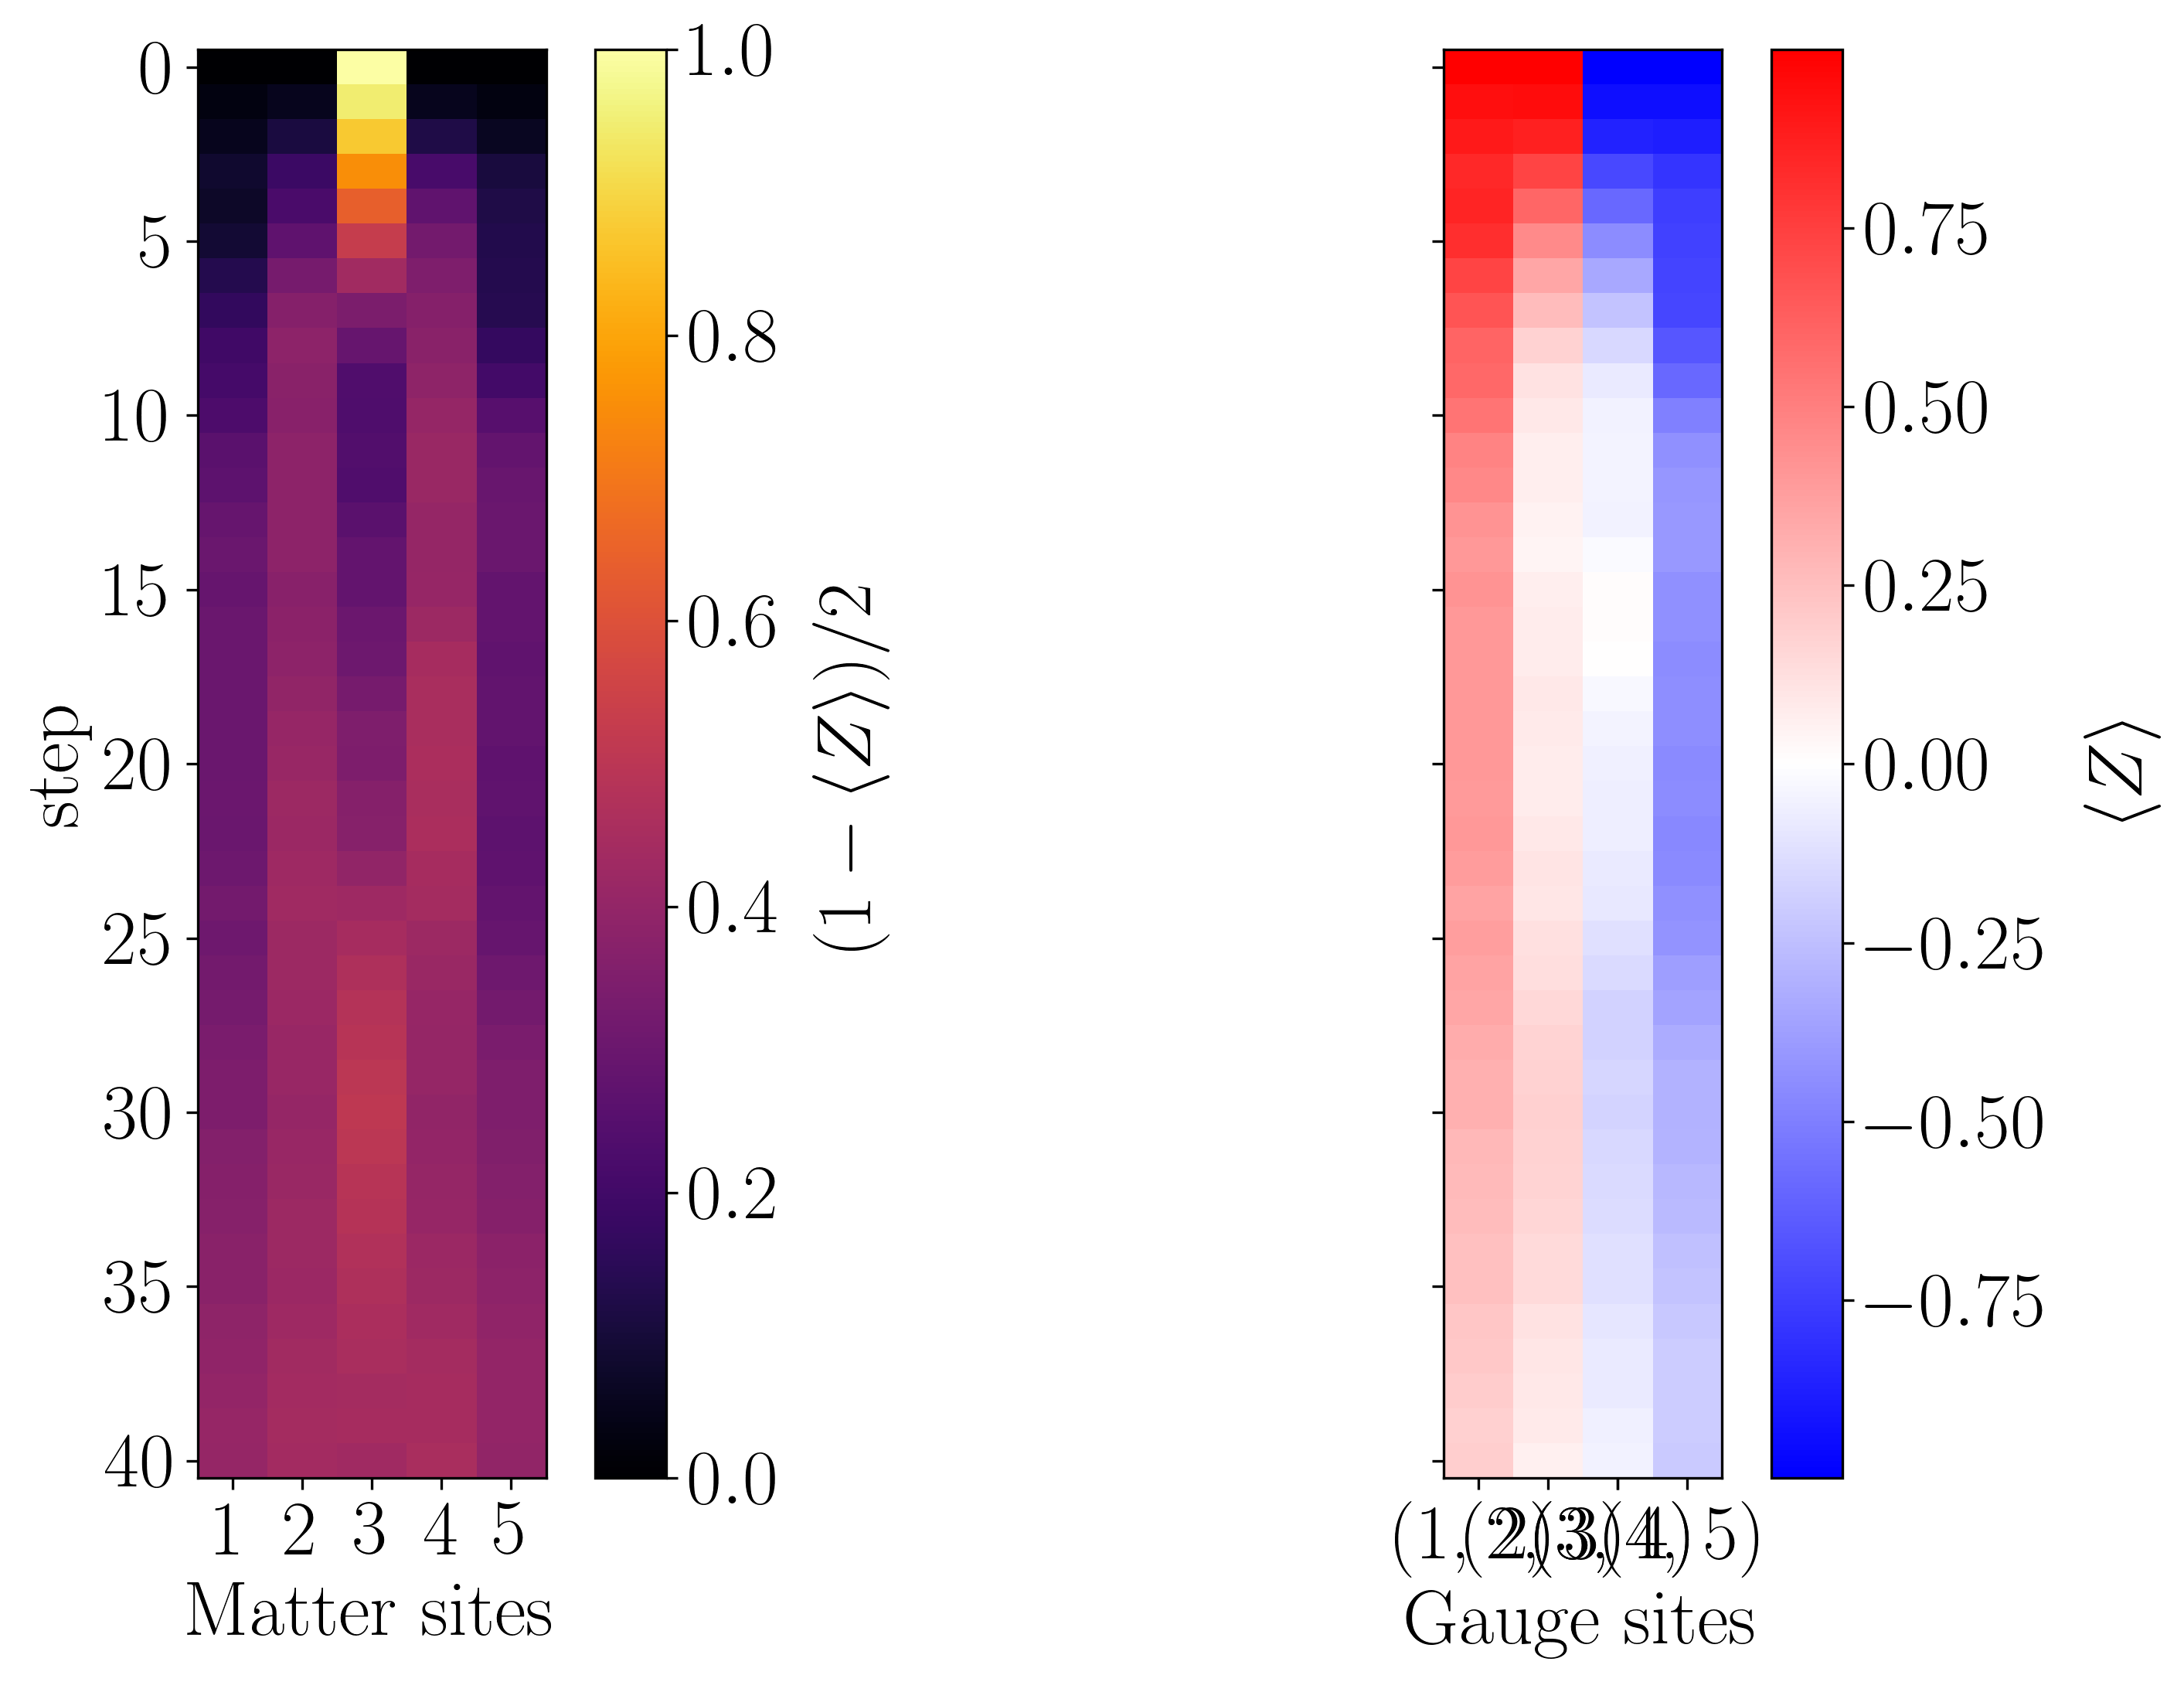

In [68]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(sim_observables_zne[:, 0], cbar_range_matter=[0, 1])

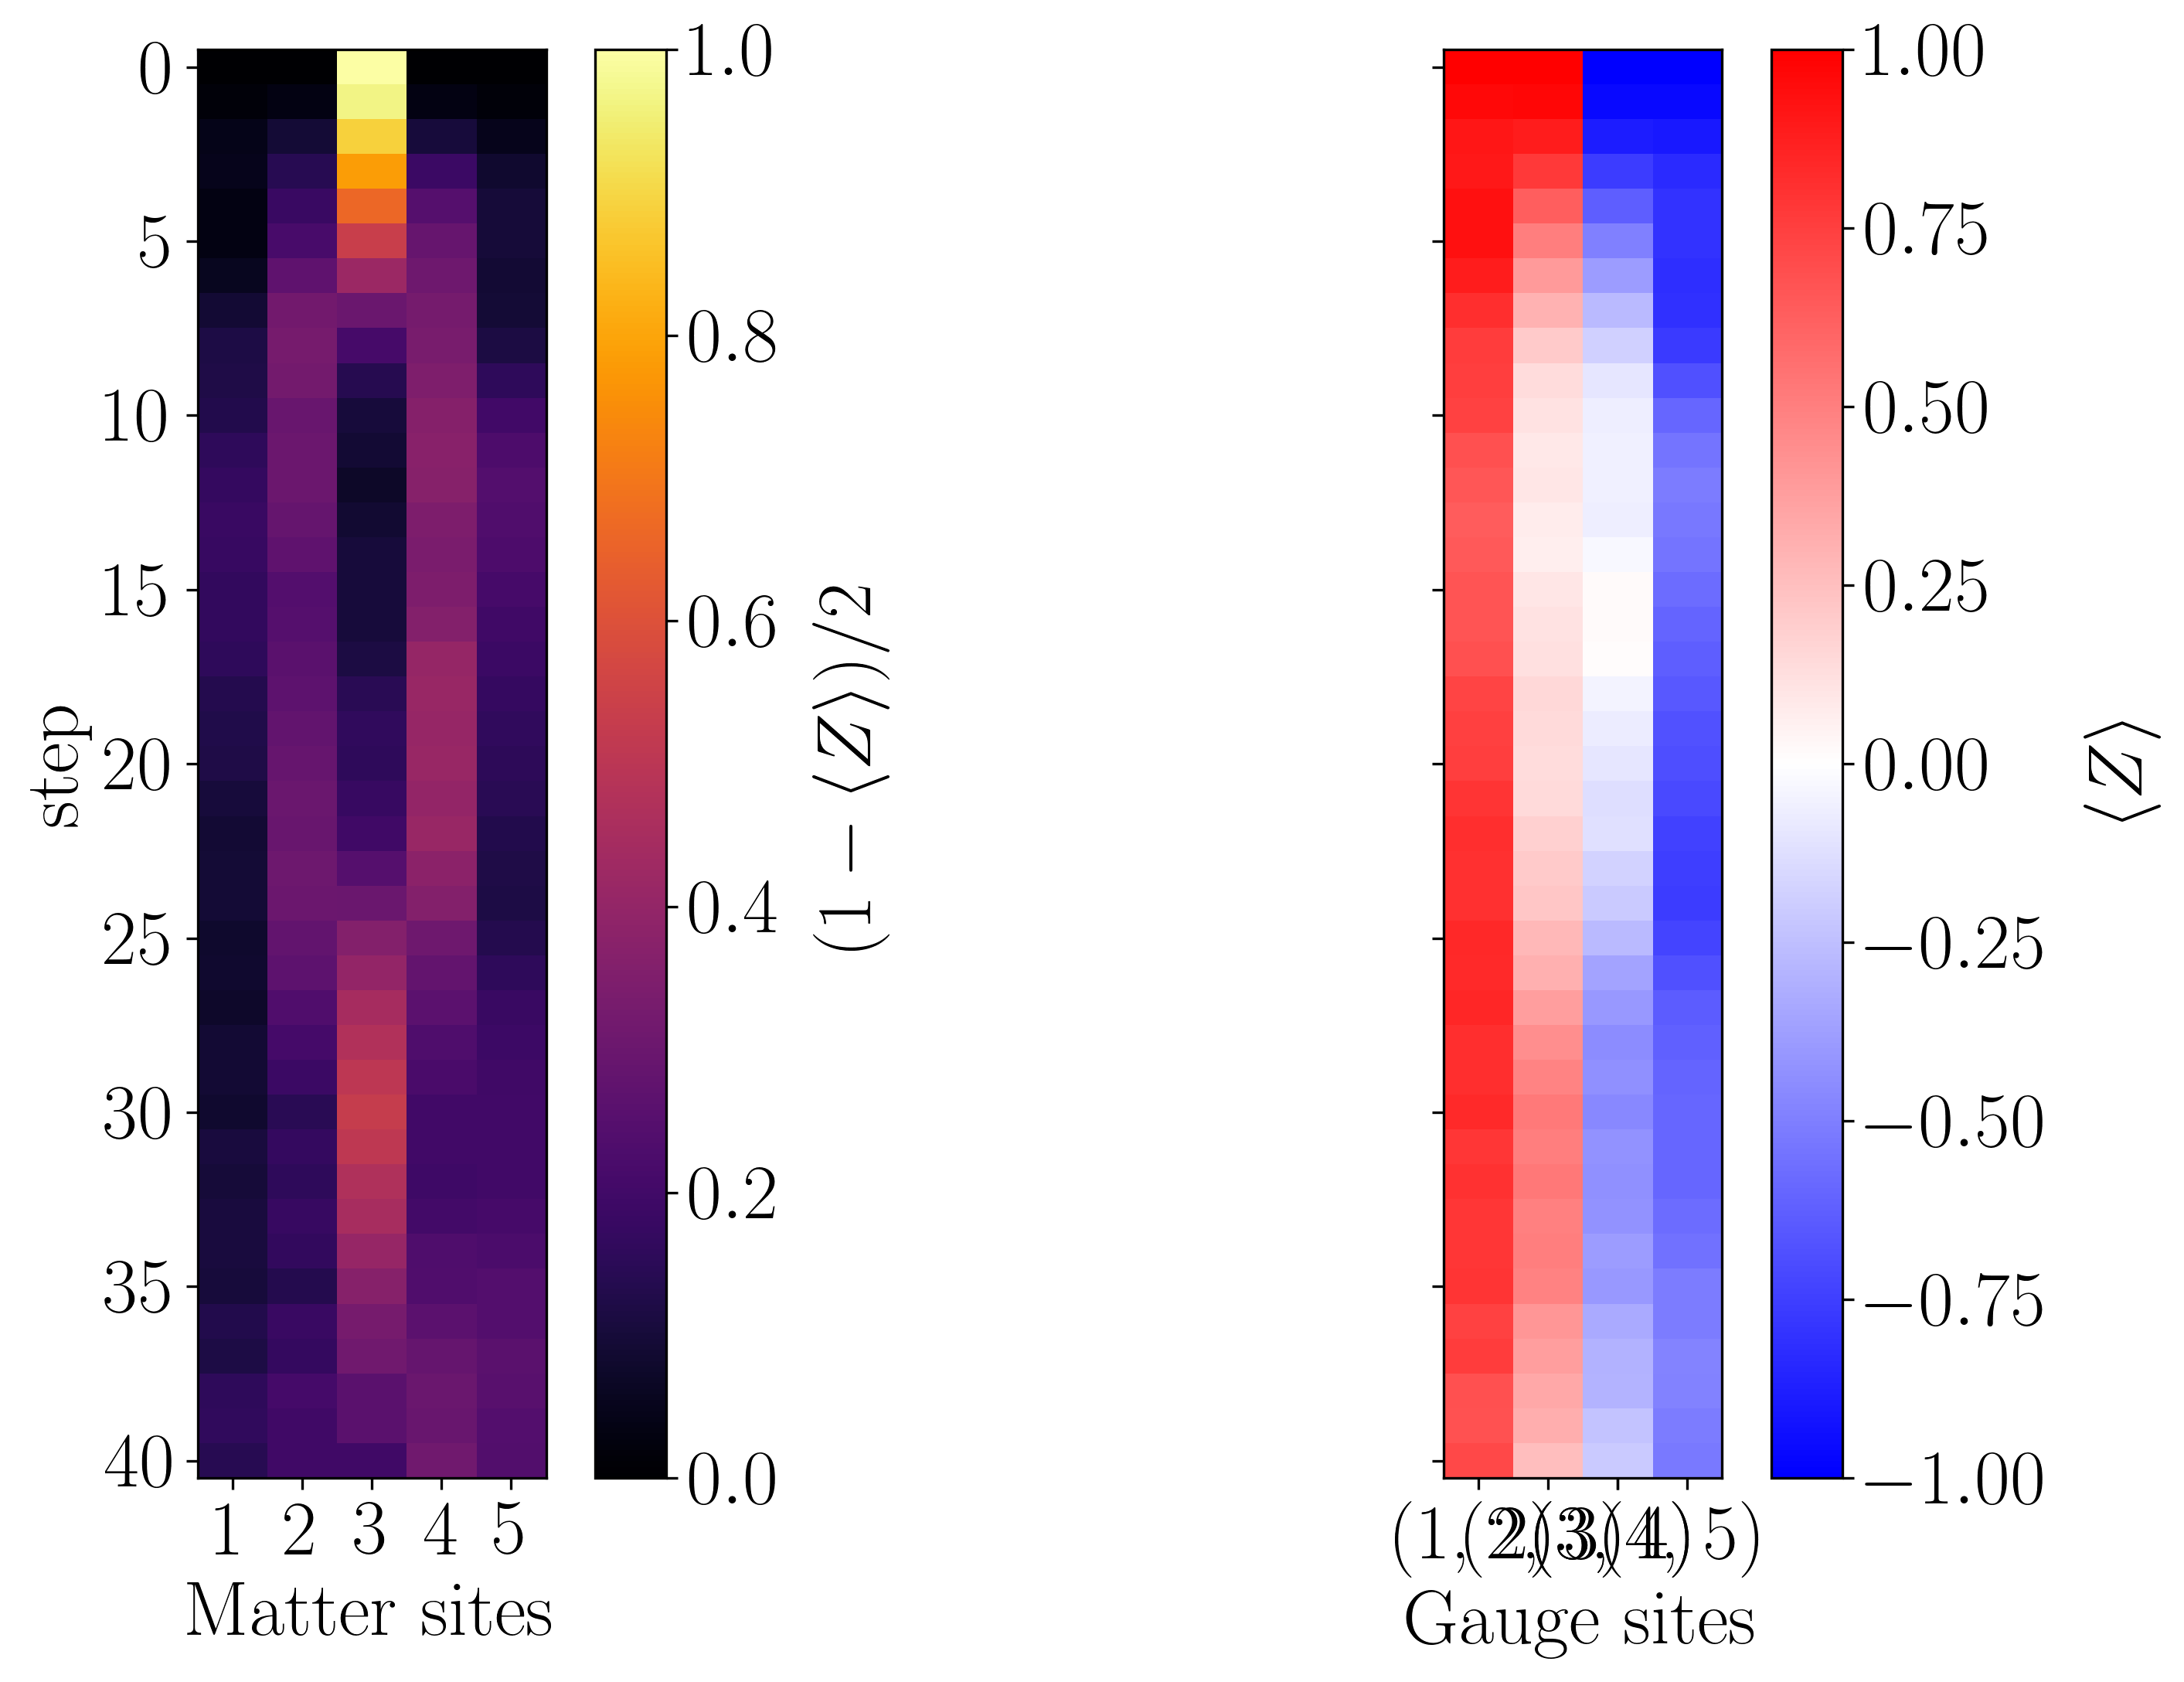

In [69]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(clean_observables_zne[:, 0], cbar_range_matter=[0, 1])

## Is there a trend?

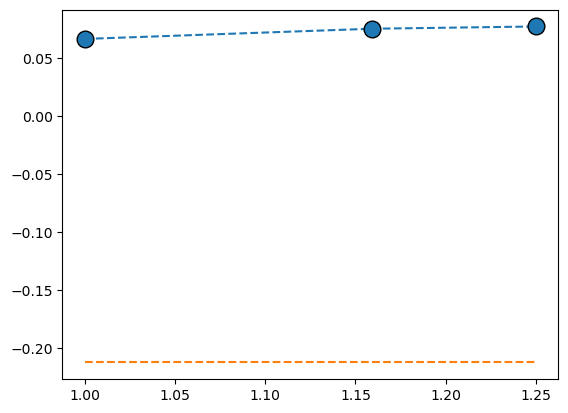

In [104]:
step = 35
site_ind = 4

plt.plot(final_amplification_levels[step], sim_observables_zne[step, :, site_ind], "o--", markeredgecolor="black", markersize=12)
plt.plot(final_amplification_levels[step], [exact_observables[step, site_ind]]*noise_amplification_factors.shape[1], "--", markeredgecolor="black", markersize=12)

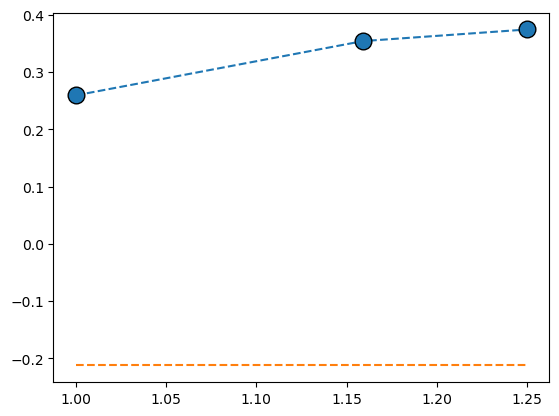

In [105]:
plt.plot(final_amplification_levels[step], clean_observables_zne[step, :, site_ind], "o--", markeredgecolor="black", markersize=12)
plt.plot(final_amplification_levels[step], [exact_observables[step, site_ind]]*noise_amplification_factors.shape[1], "--", markeredgecolor="black", markersize=12)

In [106]:
from scipy.optimize import curve_fit

def exponential_zne(noise_amplified_observables, amplification_levels):
    if noise_amplified_observables.shape != amplification_levels.shape:
        raise ValueError("The noise amplified observables and amplification levels arrays must have the same shape")

    noise_amplified_observables = np.array(noise_amplified_observables).flatten()
    amplification_levels = np.array(amplification_levels).flatten()

    def curve(x, *extrapolation_coefficients):
        bias = extrapolation_coefficients[0]
        return bias + np.sum([coeff * np.exp(-amplvl*x) for coeff, amplvl in zip(extrapolation_coefficients[1:], amplification_levels[1:])], axis=0)
    
    opt_coeffs, covariance_matrix = curve_fit(curve, amplification_levels, noise_amplified_observables, p0=[0] + [2]*(len(amplification_levels)-1))
    zero_noise_value = curve(0, *opt_coeffs)
    # TODO: Really addressing this
    znvalue_std = np.ones(len(opt_coeffs)) @ covariance_matrix @ np.ones(len(opt_coeffs))
    znvalue_std = np.sqrt(znvalue_std)
    return zero_noise_value, opt_coeffs, znvalue_std

def polynomial_zne(noise_amplified_observables, amplification_levels, degree=1):
    noise_amplified_observables = np.array(noise_amplified_observables).flatten()
    if degree + 1 > len(noise_amplified_observables):
        raise ValueError("degree + 1 must be less than the number of interpolation points")
    
    def curve(x, *extrapolation_coefficients):
        return np.sum([coeff * x**i for i, coeff in enumerate(extrapolation_coefficients)], axis=0)

    opt_coeffs, covariance_matrix = curve_fit(curve, amplification_levels, noise_amplified_observables, p0=[0]*(degree+1))
    zero_noise_value = curve(0, *opt_coeffs)
    # TODO: Really addressing this
    znvalue_std = np.ones(len(opt_coeffs)) @ covariance_matrix @ np.ones(len(opt_coeffs))
    znvalue_std = np.sqrt(znvalue_std)
    return zero_noise_value, opt_coeffs, znvalue_std

In [107]:
zne_value, opt_coeffs, znval_std = exponential_zne(clean_observables_zne[step, :, site_ind], final_amplification_levels[step])

/var/folders/t9/xqv32vzn2pb091tj9_rz1_zh0000gn/T/ipykernel_58137/3197921061.py:14: OptimizeWarning: Covariance of the parameters could not be estimated
  opt_coeffs, covariance_matrix = curve_fit(curve, amplification_levels, noise_amplified_observables, p0=[0] + [2]*(len(amplification_levels)-1))


In [108]:
zne_value

-4.816488108827628

In [109]:
opt_coeffs

array([ -1.0182532 ,  86.77438938, -90.57262429])

In [110]:
def curve(x, *extrapolation_coefficients):
    bias = extrapolation_coefficients[0]
    return bias + np.sum([coeff * np.exp(-amplvl*x) for coeff, amplvl in zip(extrapolation_coefficients[1:], final_amplification_levels[step])], axis=0)

In [111]:
curve(0, *opt_coeffs)

-4.816488108827628

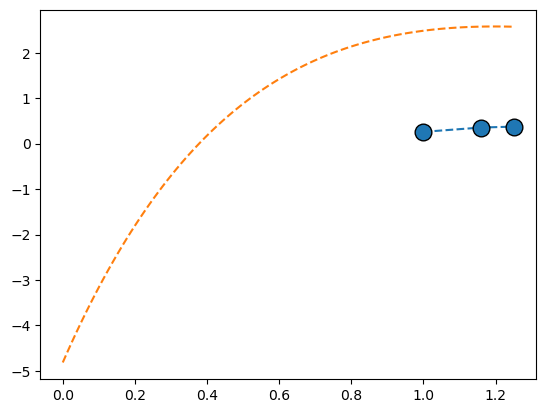

In [112]:
plt.plot(final_amplification_levels[step], clean_observables_zne[step, :, site_ind], "o--", markeredgecolor="black", markersize=12)
plt.plot(np.linspace(0, final_amplification_levels[step][-1], 100), curve(np.linspace(0, final_amplification_levels[step][-1], 100), *opt_coeffs), "--", markeredgecolor="black", markersize=12)
# plt.plot([0], [zne_value], "o", markeredgecolor="black", markersize=12)

In [113]:
zne_value, opt_coeffs_clean, znval_std = polynomial_zne(clean_observables_zne[step, :, site_ind], final_amplification_levels[step], 1)
zne_value

-0.2104601580240431

In [114]:
zne_value, opt_coeffs_sim, znval_std = polynomial_zne(sim_observables_zne[step, :, site_ind], final_amplification_levels[step], 1)
zne_value

0.022570036789088605

In [115]:
def curve(x, *extrapolation_coefficients):
        return np.sum([coeff * x**i for i, coeff in enumerate(extrapolation_coefficients)], axis=0)

In [116]:
clean_observables_zne

array([[[ 1.00018686,  1.00018686,  1.00010682, ...,  0.99981309,
         -0.9996797 ,  0.9996797 ],
        [ 0.99997331,  0.99997331,  0.99954628, ...,  0.99951958,
         -0.99951963,  0.99951963],
        [ 0.99994663,  0.99994663,  0.99986654, ...,  0.99973303,
         -0.9999733 ,  0.9999733 ]],

       [[ 0.9641371 ,  0.9641371 ,  0.93542266, ...,  0.93492232,
         -0.96874145,  0.96874145],
        [ 0.92944626,  0.92944626,  0.87578524, ...,  0.88858414,
         -0.9472226 ,  0.9472226 ],
        [ 0.94131321,  0.94131321,  0.8979859 , ...,  0.90199521,
         -0.95572632,  0.95572632]],

       [[ 0.90809812,  0.90809812,  0.80698651, ...,  0.79625995,
         -0.90198069,  0.90198069],
        [ 0.87645967,  0.87645967,  0.73282337, ...,  0.71132434,
         -0.86203686,  0.86203686],
        [ 0.89365427,  0.89365427,  0.7840587 , ...,  0.77310713,
         -0.89061901,  0.89061901]],

       ...,

       [[ 0.68597277,  0.68597277,  0.5804159 , ...,  0.4018945

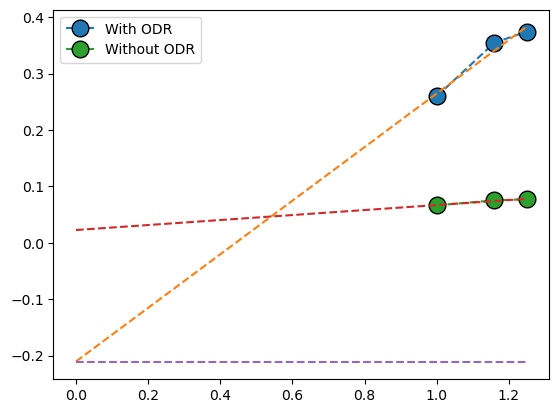

In [117]:
x = np.linspace(0, final_amplification_levels[step][-1], 100)

plt.plot(final_amplification_levels[step], clean_observables_zne[step, :, site_ind], "o--", markeredgecolor="black", markersize=12, label="With ODR")
plt.plot(x, curve(x, *opt_coeffs_clean), "--", markeredgecolor="black", markersize=12)
plt.plot(final_amplification_levels[step], sim_observables_zne[step, :, site_ind], "o--", markeredgecolor="black", markersize=12, label="Without ODR")
plt.plot(x, curve(x, *opt_coeffs_sim), "--", markeredgecolor="black", markersize=12)
plt.plot(x, [exact_observables[step, site_ind]]*len(x), "--", markeredgecolor="black", markersize=12)
plt.legend()
# plt.plot([0], [zne_value], "o", markeredgecolor="black", markersize=12)

In [84]:
def polynomial_extrapolate_observables(observable_matrix_zne, noise_amplification_factors, degree=1):
    """
    Returns an observable matrix with the extrapolated values from the observable_matrix_nez data
    -------

    observable_matrix_zne : np.ndarray
        Matrix of shape (steps, zne_points, observables) with the observable values to perform
    noise_amplification_factors : np.ndarray
        Matrix of shape (steps, zne_points) with the amplification factors for each observable
    max_degree : int
        Degree of the polynomial used for extrapolation
    """

    if observable_matrix_zne.shape[:-1] != noise_amplification_factors.shape:
        raise ValueError("The shape of noise_amplification_factors and the first two dimensions of observable_matrix_zne must be the same")

    extrapolated_observables = np.zeros((observable_matrix_zne.shape[0], observable_matrix_zne.shape[2]))
    extrapolated_observables_std = np.zeros_like(extrapolated_observables)
    for istep in range(observable_matrix_zne.shape[0]):
        for iobs in range(observable_matrix_zne.shape[2]):
            zne_value, opt_coeffs, znval_std = polynomial_zne(observable_matrix_zne[istep, :, iobs], noise_amplification_factors[istep], degree)
            extrapolated_observables[istep, iobs] = zne_value
            extrapolated_observables_std[istep, iobs] = znval_std
    
    return extrapolated_observables, extrapolated_observables_std
        

In [85]:
clean_extrapolated_observables, clean_extrapolated_observables_std = polynomial_extrapolate_observables(clean_observables_zne, final_amplification_levels, 1)
sim_extrapolated_observables, sim_extrapolated_observables_std = polynomial_extrapolate_observables(sim_observables_zne, final_amplification_levels, 1)
odr_extrapolated_observables, odr_extrapolated_observables_std = polynomial_extrapolate_observables(odr_observables_zne, final_amplification_levels, 1)

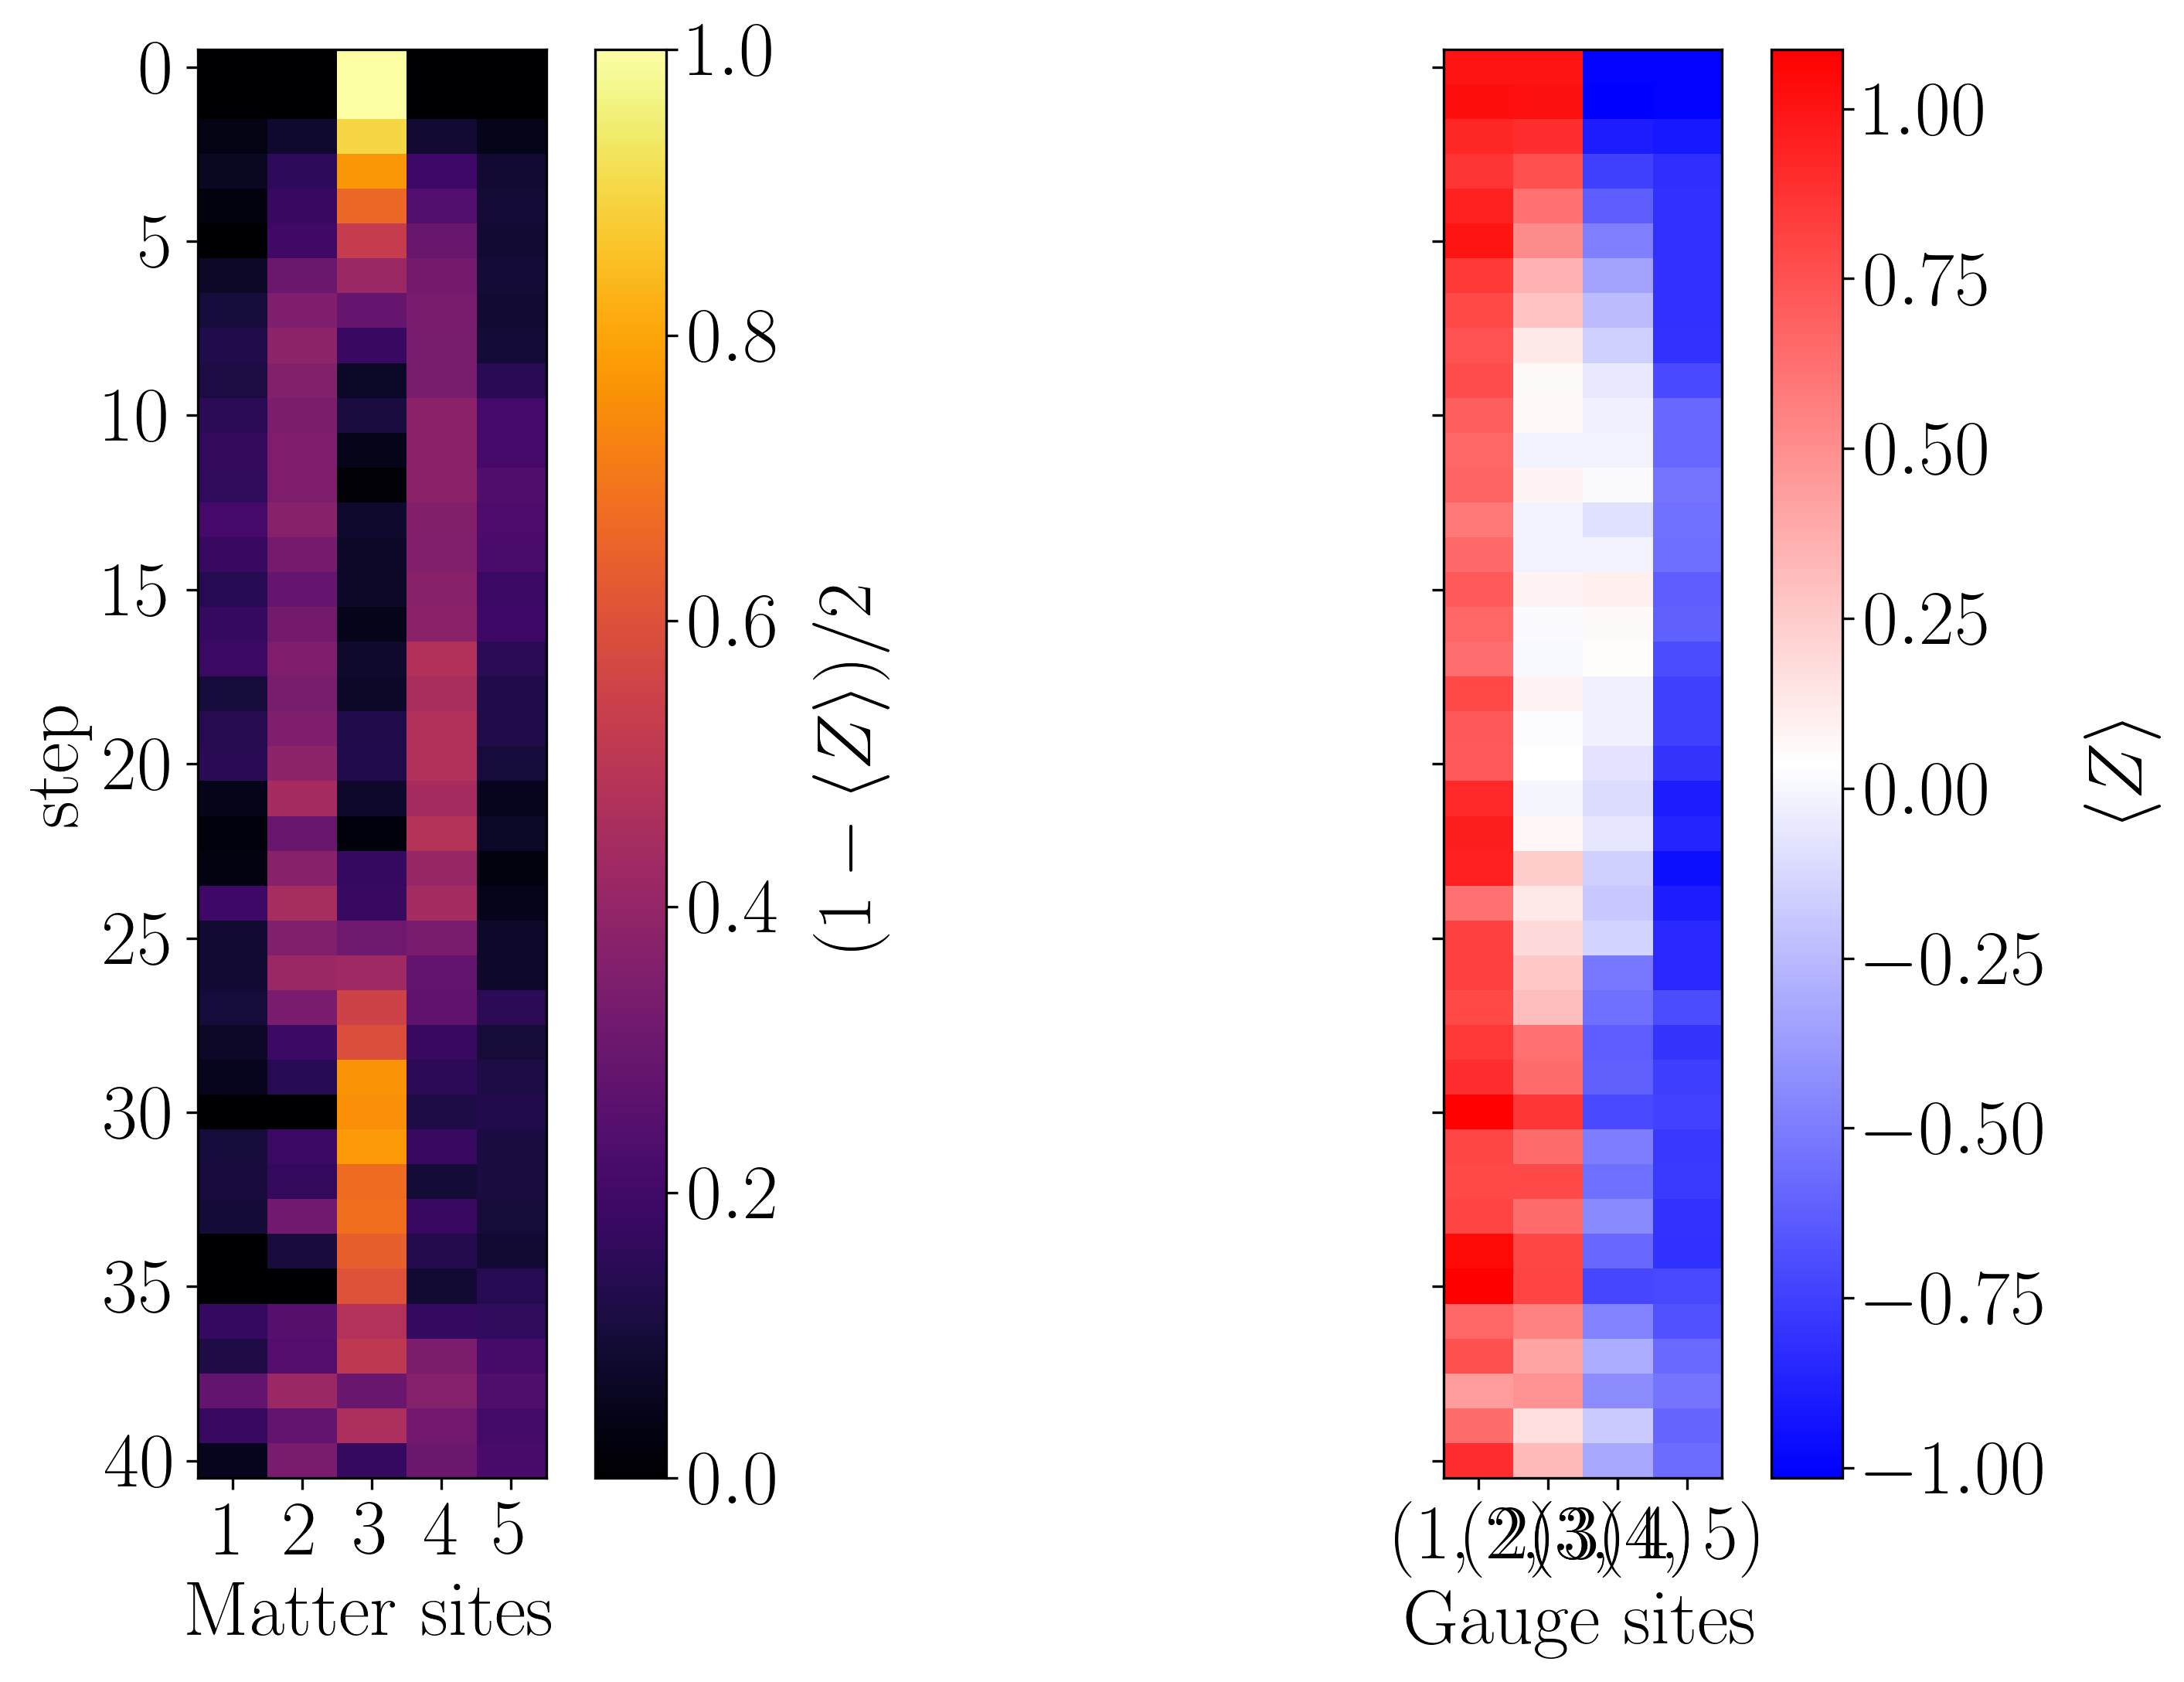

In [86]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(clean_extrapolated_observables, cbar_range_matter=[0, 1])

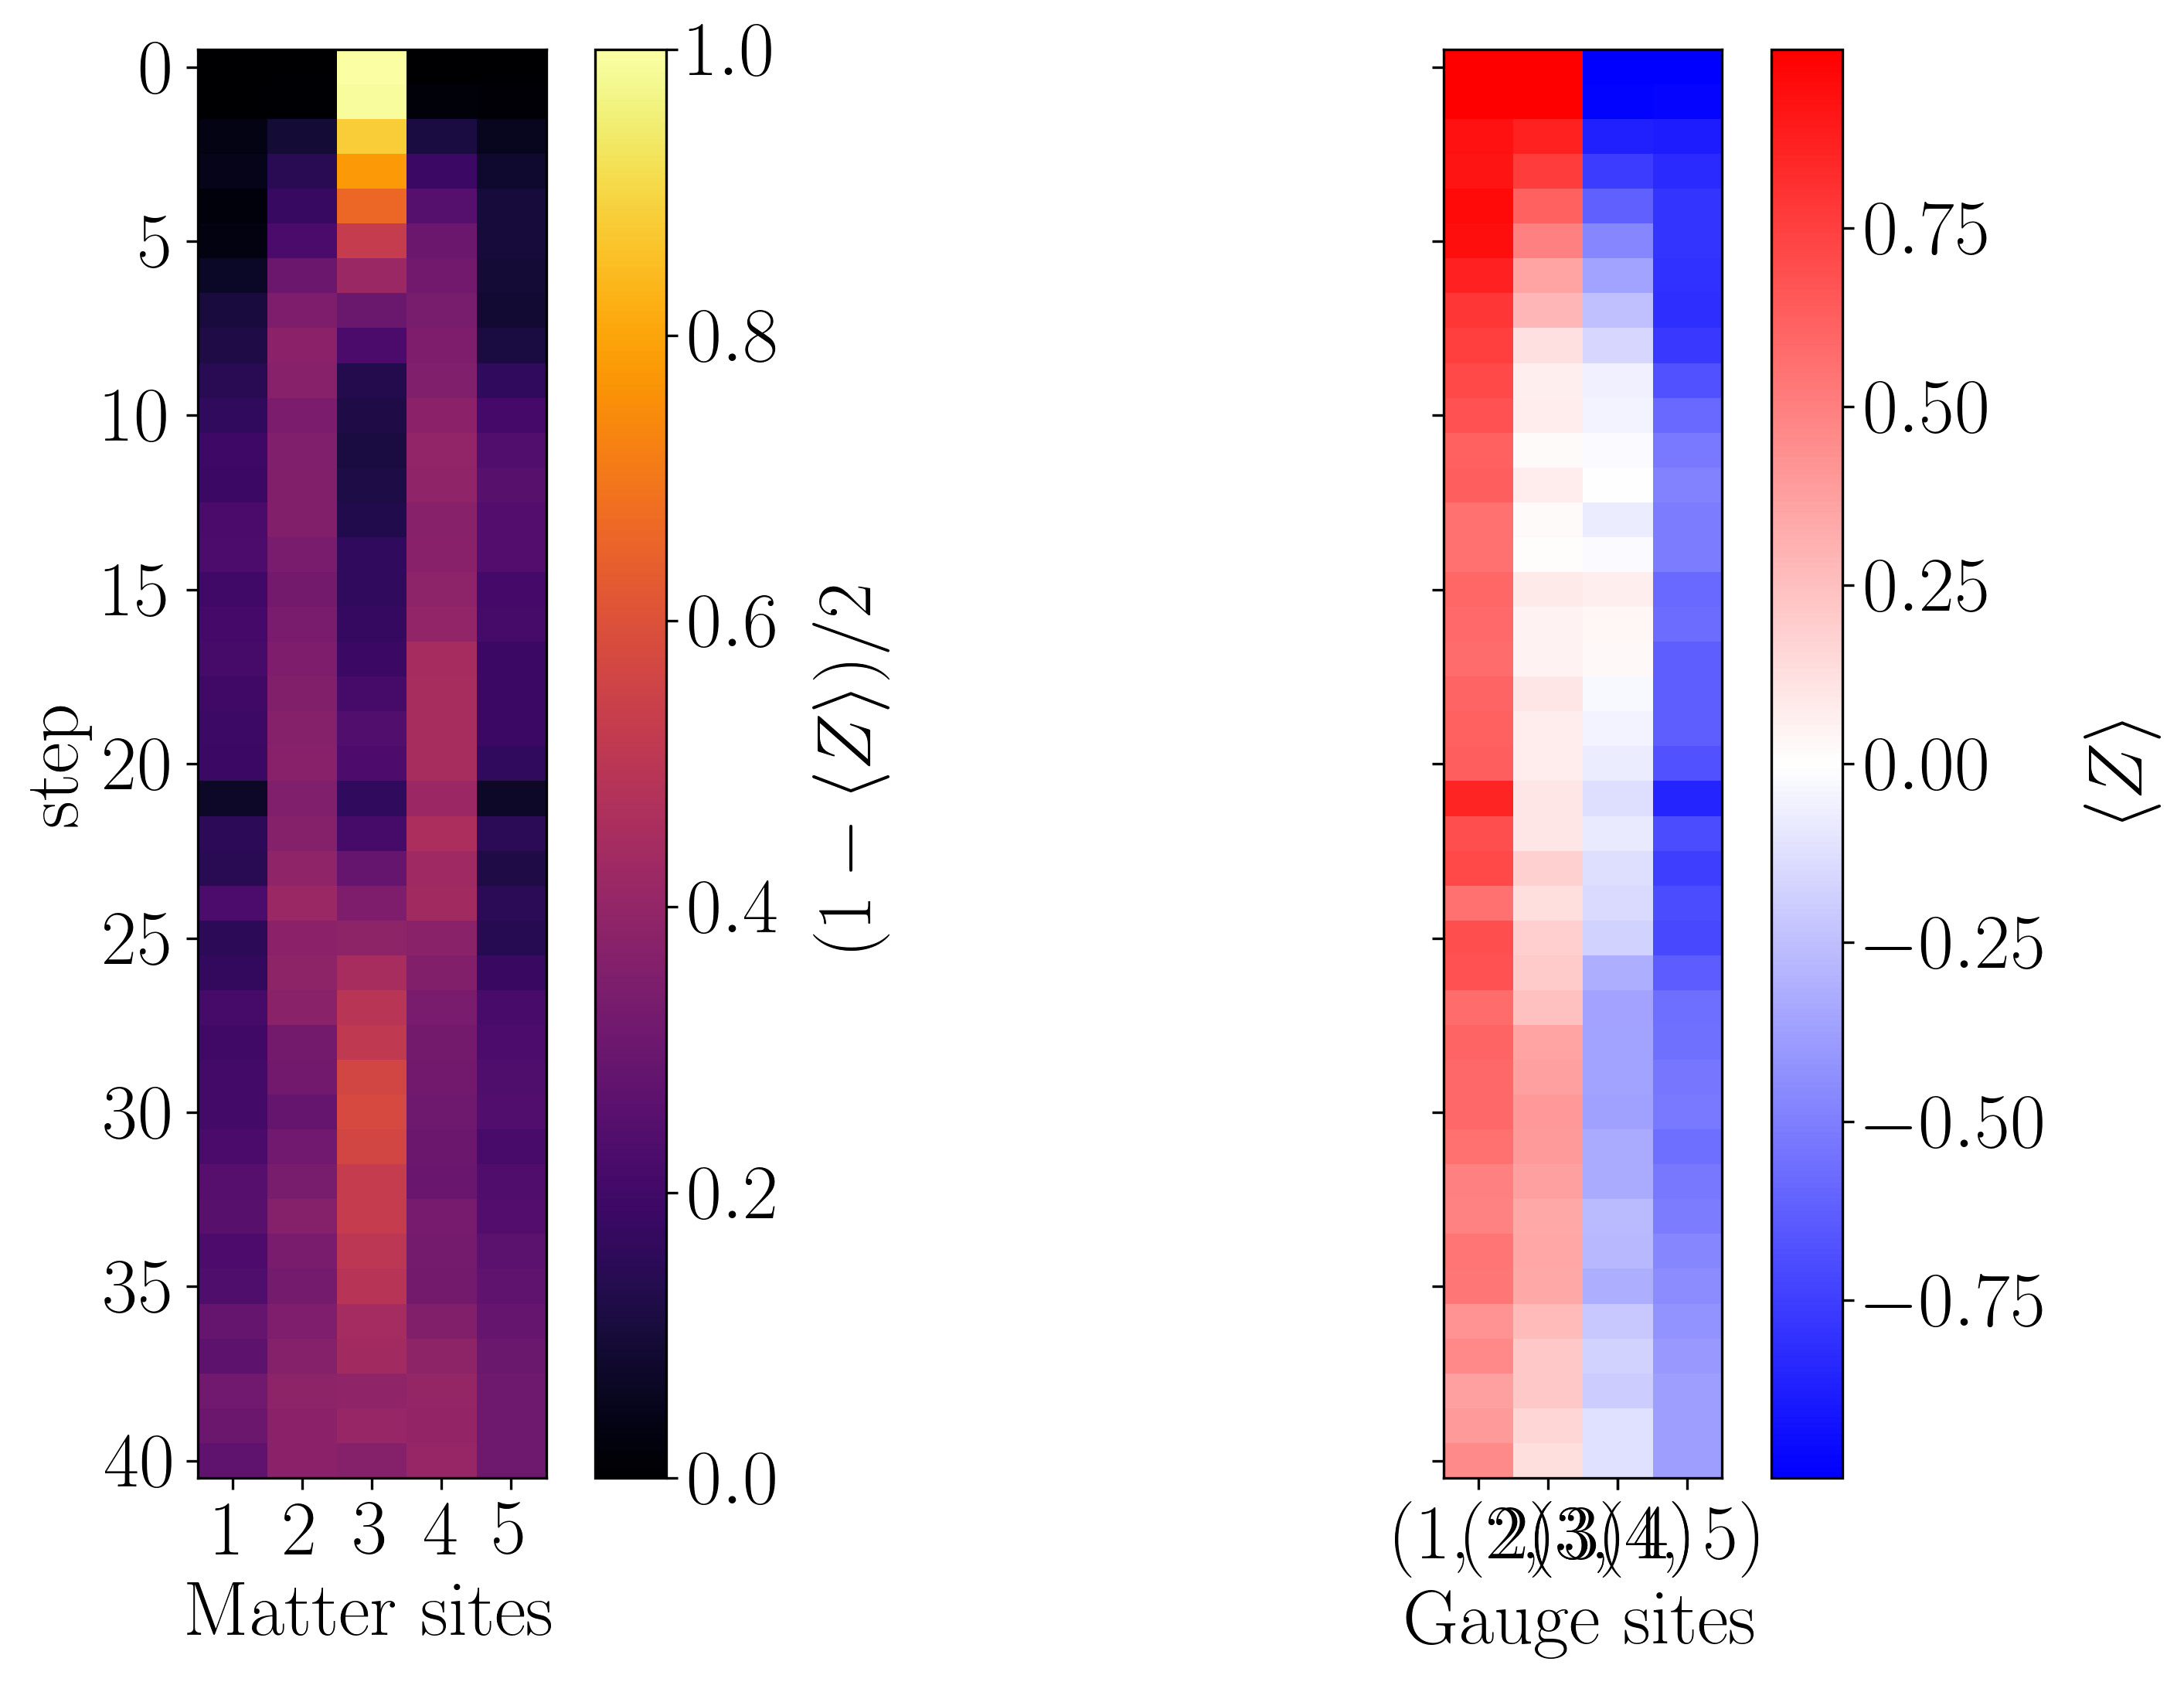

In [87]:
from z2chain.plotting import x_t_separated_plot

x_t_separated_plot(sim_extrapolated_observables, cbar_range_matter=[0, 1])

In [88]:
opposite_order_clean_observables = np.zeros((steps+1, len(observable_generating_funcs)))
for i in range(steps+1):
    p_arr = compute_depolarizing_probability(odr_extrapolated_observables[i], 1, 0, circuits[0, i].num_qubits)
    opposite_order_clean_observables[i] = renormalize_observable(sim_extrapolated_observables[i], p_arr, 0, circuits[0, i].num_qubits, observable_range=(-1, 1), expected_observable_arr=1, observable_confidence=None)

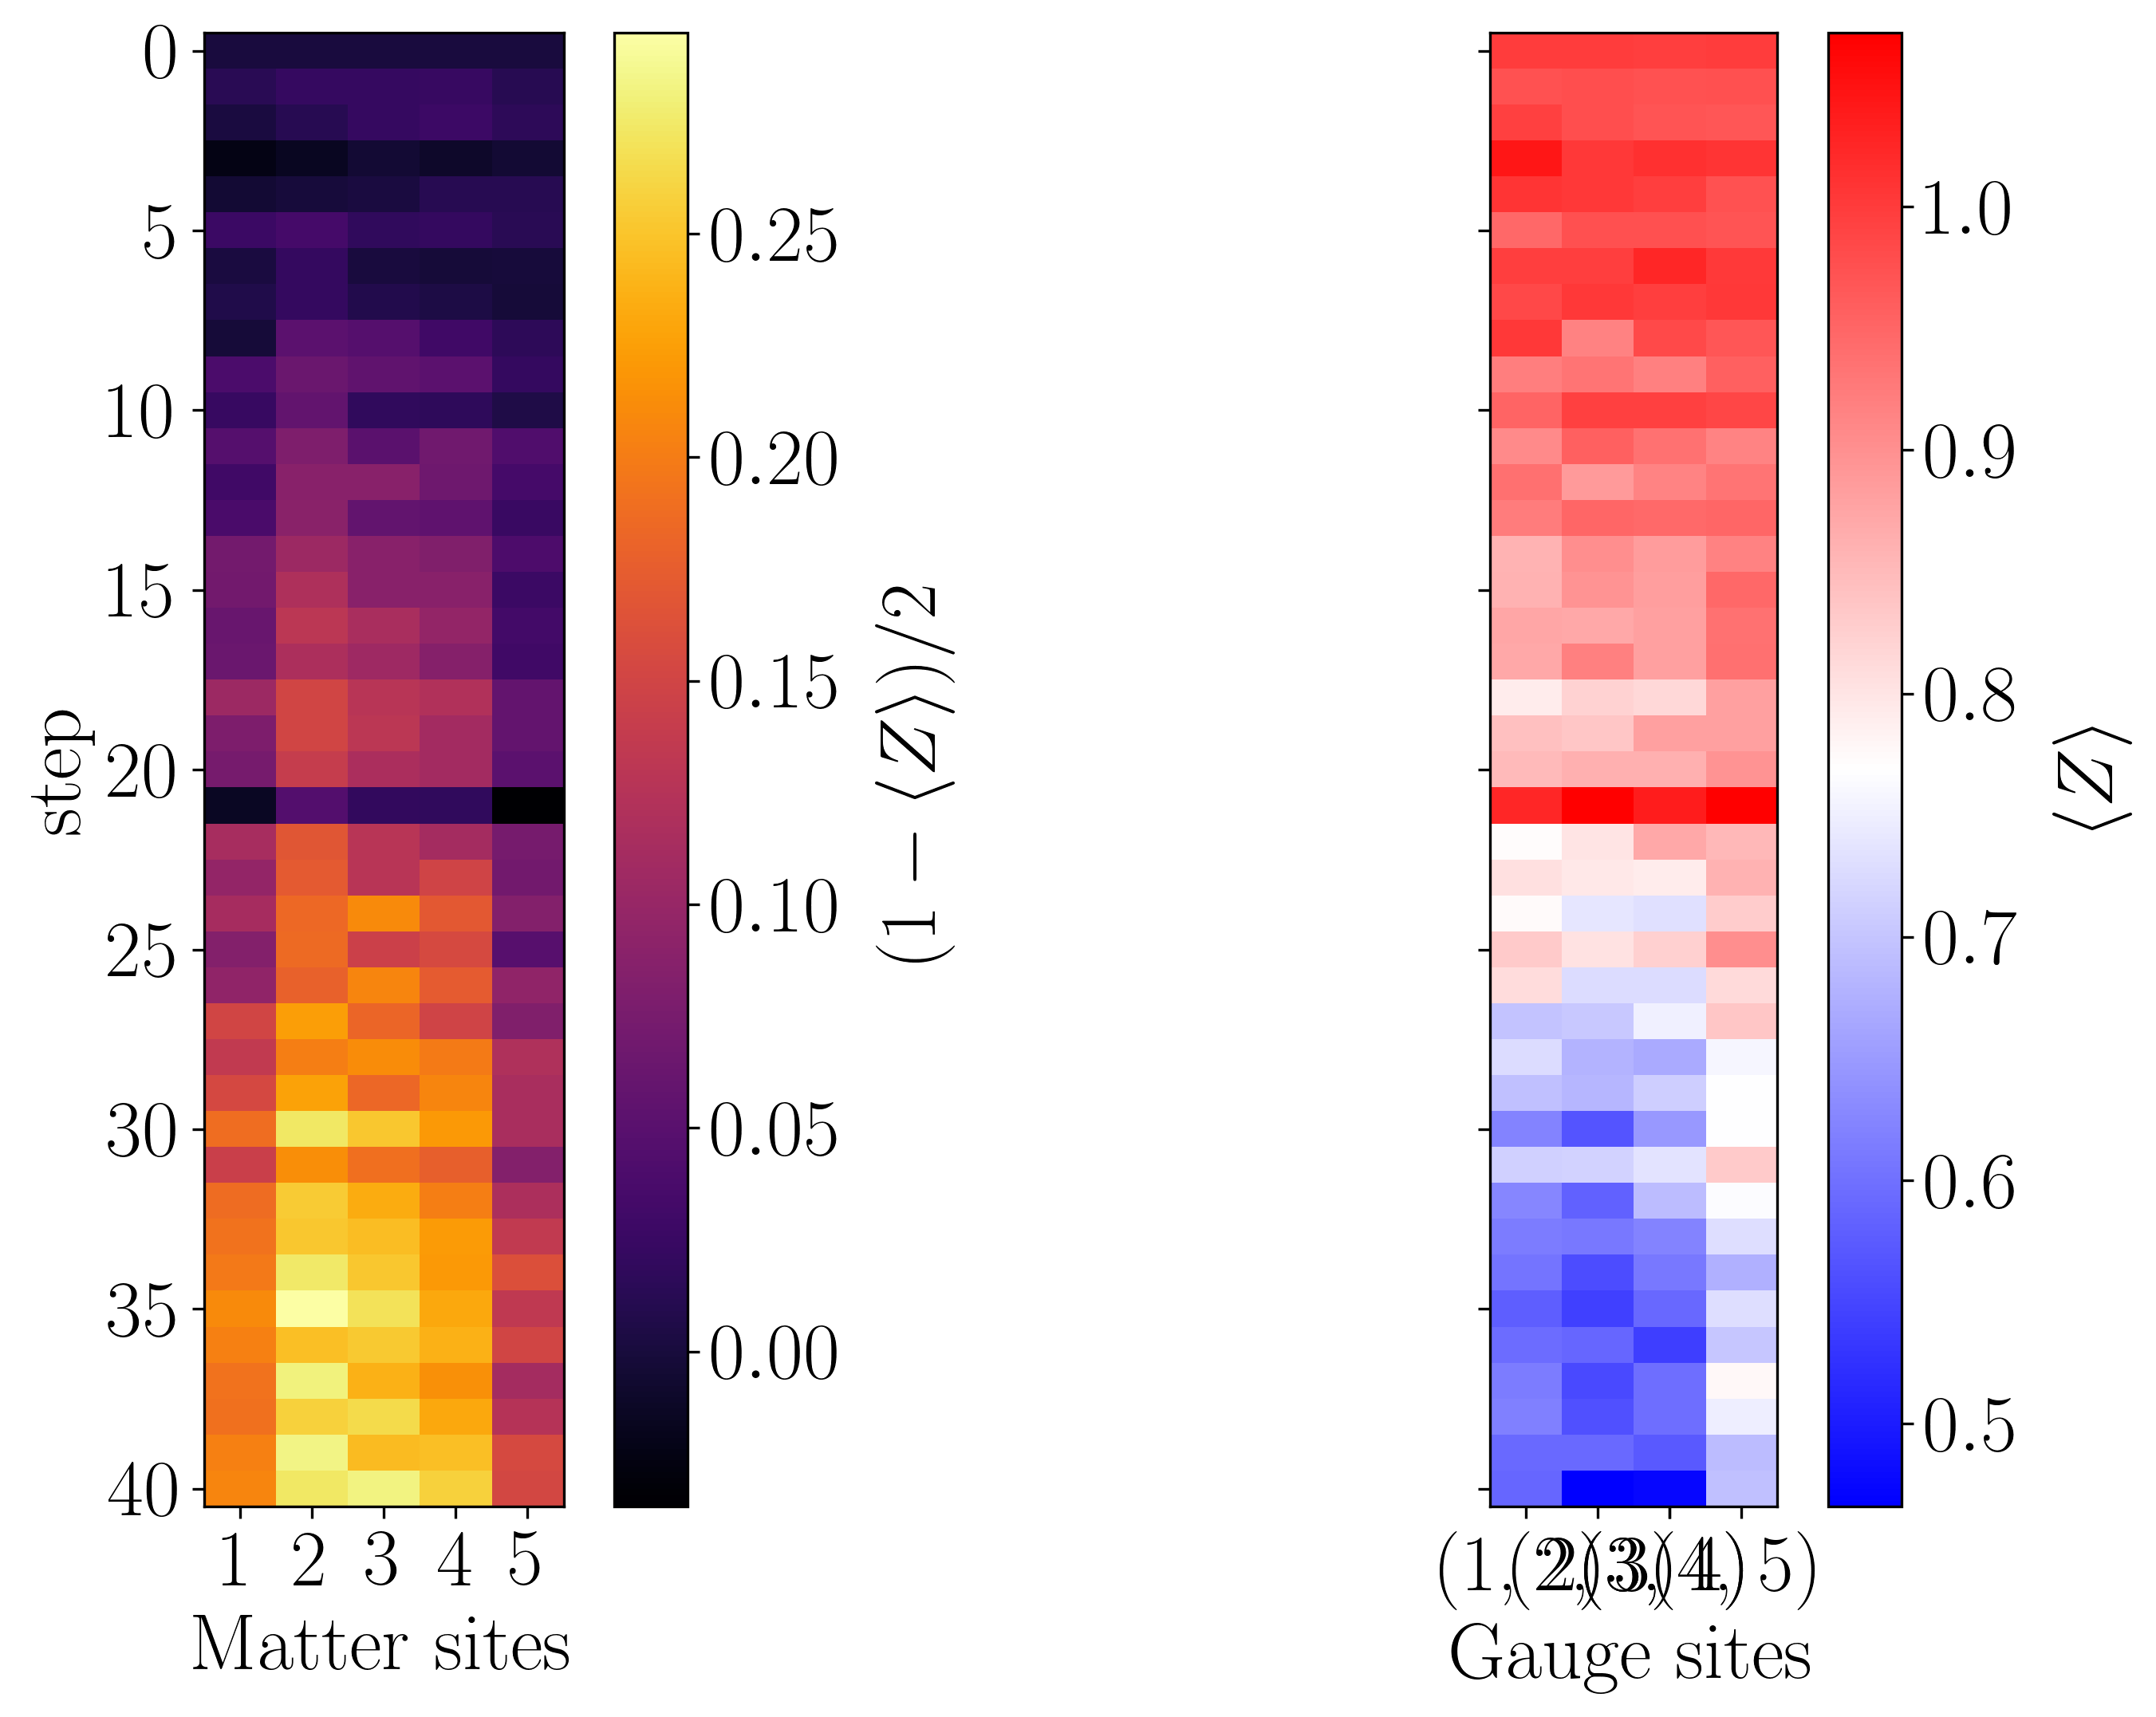

In [89]:
x_t_separated_plot(odr_extrapolated_observables)

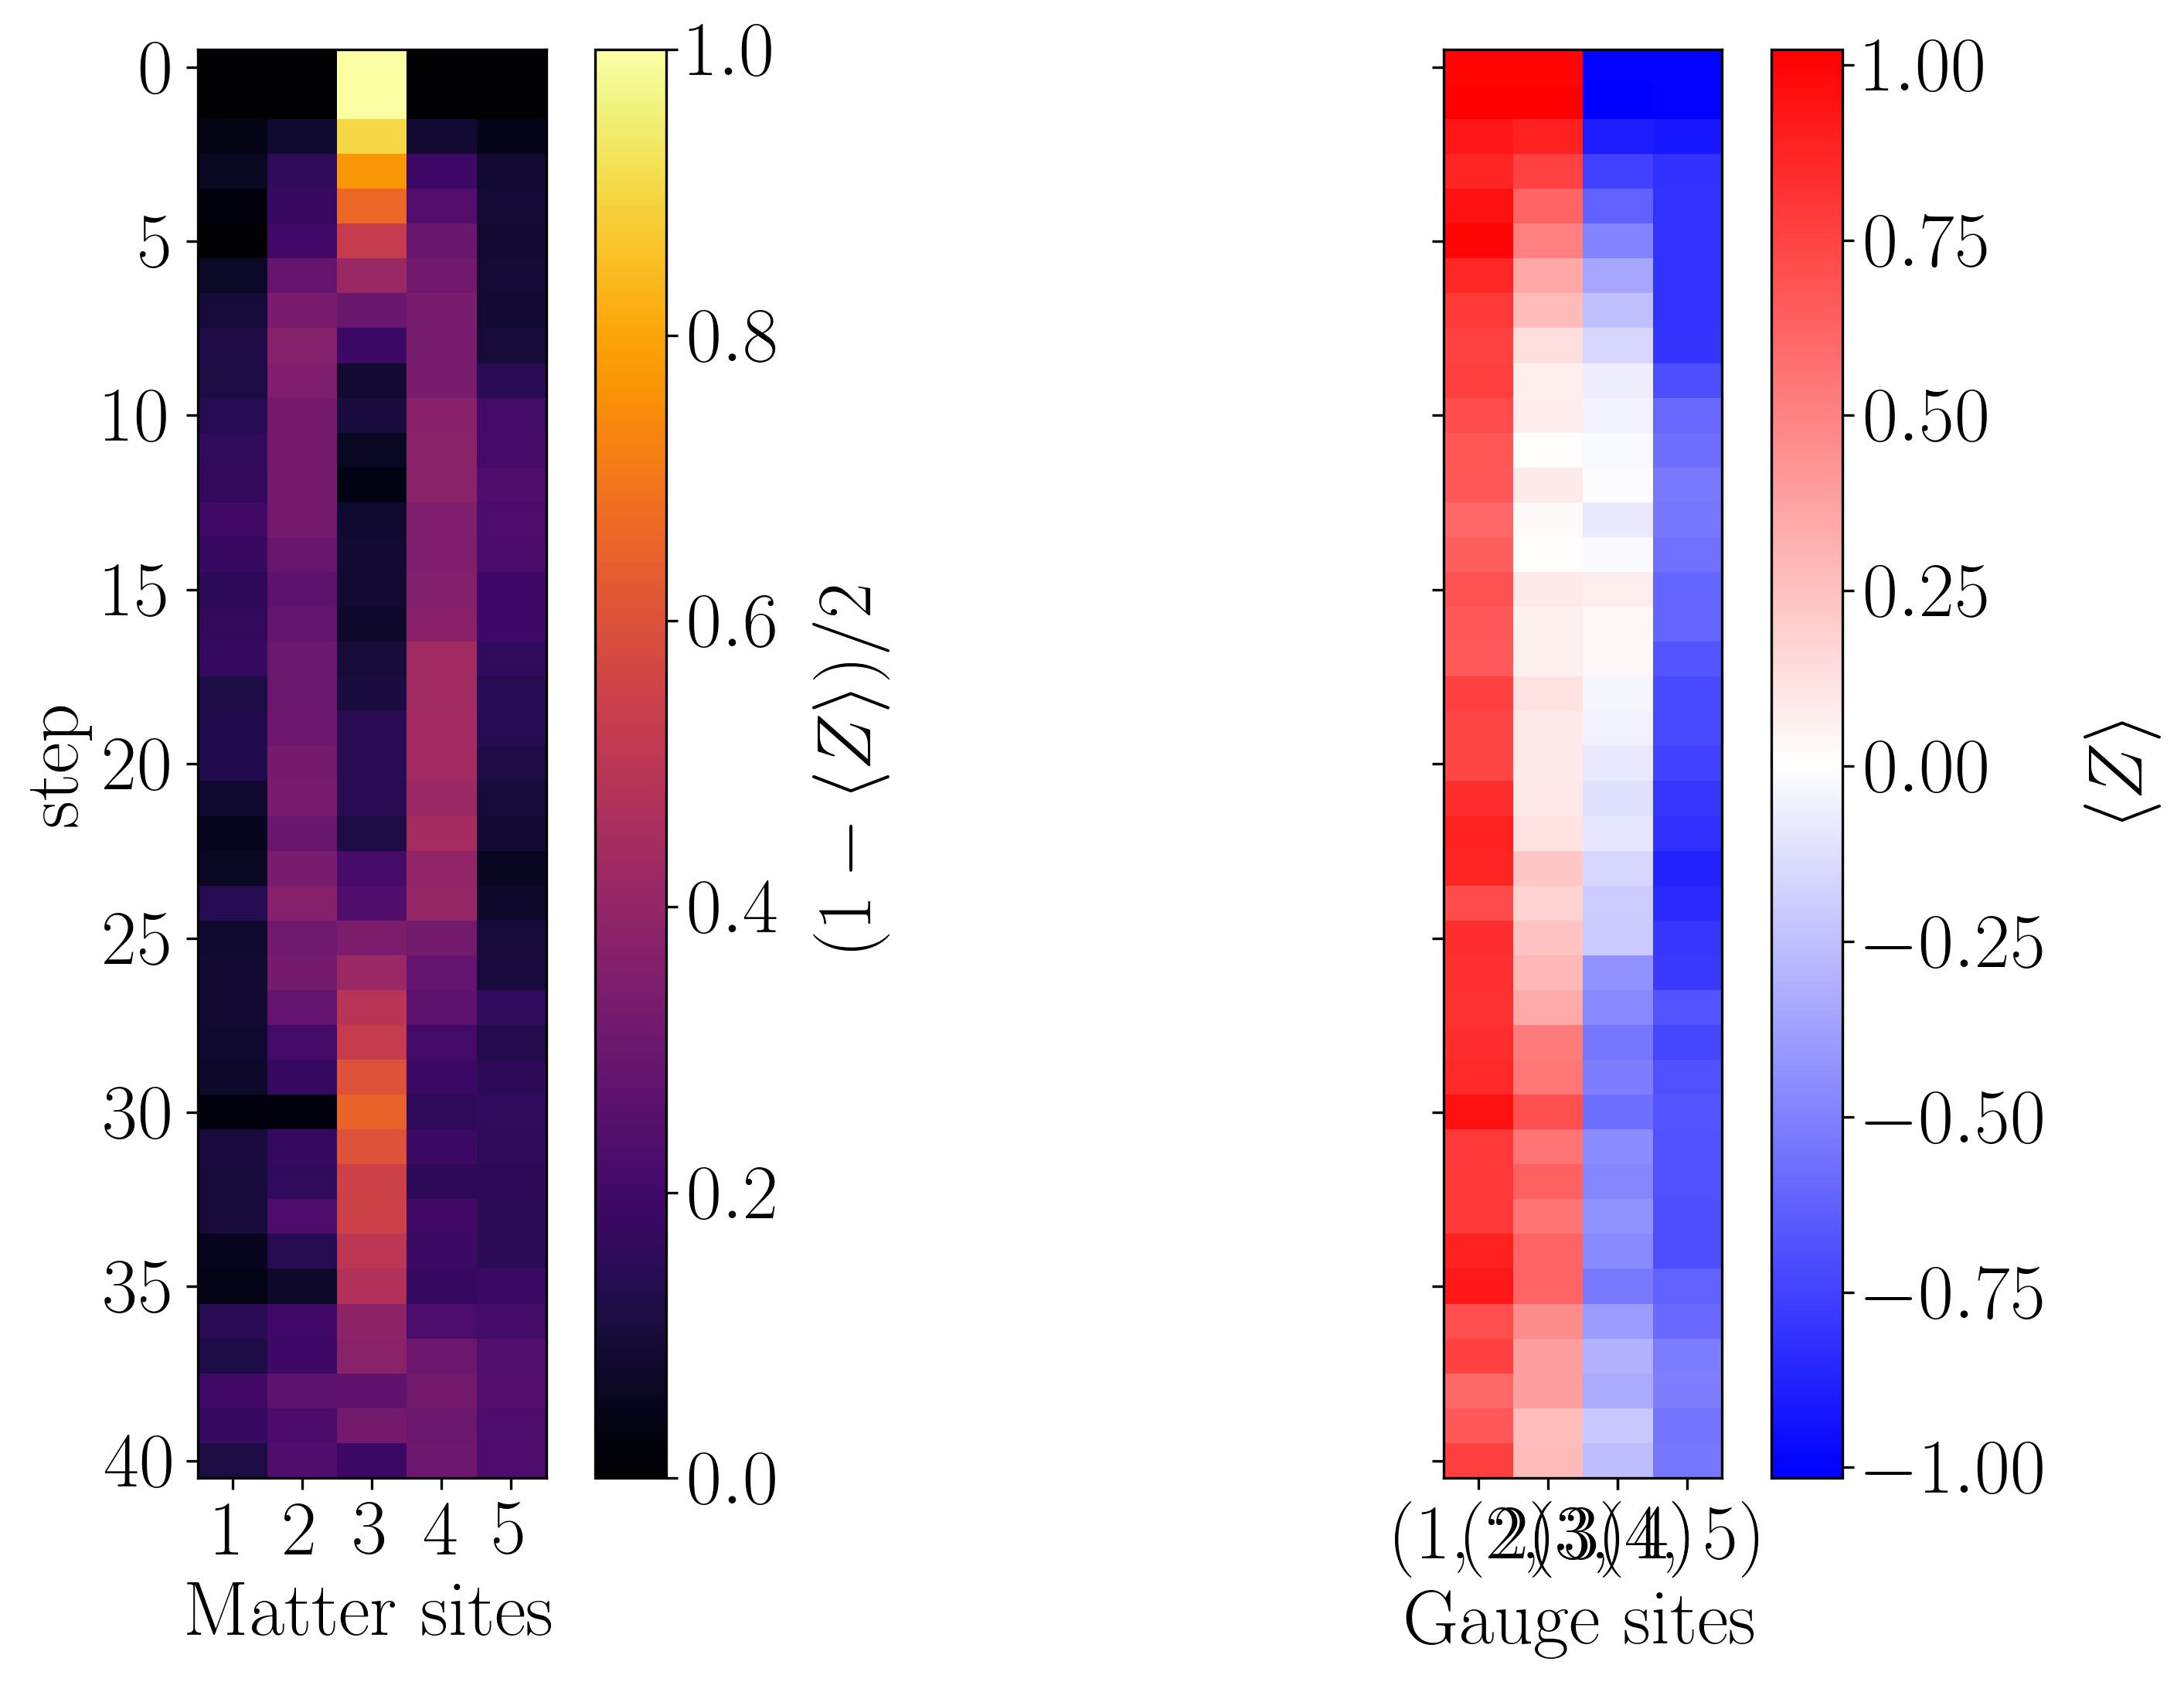

In [90]:
x_t_separated_plot(opposite_order_clean_observables, cbar_range_matter=[0, 1])

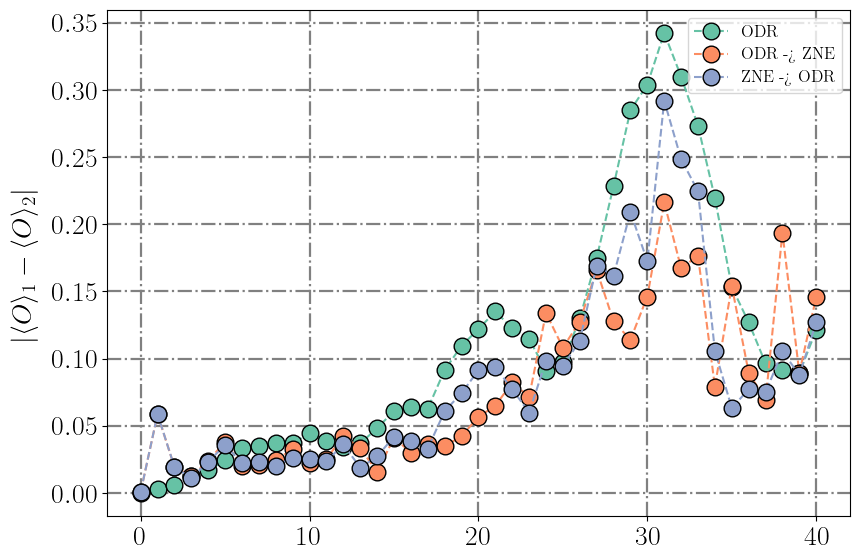

In [ ]:
from utils.plotting import plot_mean_deviations

plot_mean_deviations([clean_observables_zne[:, 0, :], clean_extrapolated_observables, opposite_order_clean_observables], [exact_observables]*3, labels=["ODR", "ODR -> ZNE", "ZNE -> ODR"])

In [92]:
clean_observables_zne[:, 0, :].shape

(41, 9)

In [93]:
opposite_order_clean_observables.shape

(41, 9)